# Football Cards Prediction ⚽

Predict next-season yellow and red card counts from historical player-season statistics.

**Important:** this is an educational project. The dataset ends on 2021-02-06, so the 2020 season is incomplete. The notebook excludes 2020 as an observed target season and evaluates on a later season than the training data.

## 1. Imports and load the data

Expected CSV file: `appearances-selected-columns.csv`.

In Google Colab, the cell will ask you to upload the CSV if it is not already available. Do not commit a large dataset to GitHub unless its license permits redistribution.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = "appearances-selected-columns.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_candidates = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_candidates:
            raise FileNotFoundError("Please upload the appearances CSV file.")
        DATA_PATH = csv_candidates[0]
    except ImportError as exc:
        raise FileNotFoundError(
            f"Could not find {DATA_PATH}. Put the CSV beside this notebook or run it in Colab and upload the file."
        ) from exc

use_cols = [
    "game_id", "player_id", "date", "player_name",
    "yellow_cards", "red_cards"
]
df = pd.read_csv(DATA_PATH, usecols=use_cols)

print("Raw data shape:", df.shape)
display(df.head())

Raw data shape: (1116968, 6)


,game_id,player_id,date,player_name,yellow_cards,red_cards
0,2231978,38004,2012-07-03,Aurélien Joachim,0.0,0.0
1,2233748,79232,2012-07-05,Ruslan Abyshov,0.0,0.0
2,2234413,42792,2012-07-05,Sander Puri,0.0,0.0
3,2234418,73333,2012-07-05,Vegar Hedenstad,0.0,0.0
4,2234421,122011,2012-07-05,Markus Henriksen,0.0,0.0


## 2. Clean and aggregate match-level data into player-season records

A season is defined as starting in August. Each row below represents one player in one season. Since the dataset ends in February 2021, season 2020 is incomplete and is not used as a target for model evaluation.

In [2]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date", "player_id"]).copy()

for col in ["yellow_cards", "red_cards"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

df["season"] = np.where(
    df["date"].dt.month >= 8,
    df["date"].dt.year,
    df["date"].dt.year - 1
).astype(int)

print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("\nMatch appearances by season:")
display(df.groupby("season").size().rename("rows").reset_index())

player_season = (
    df.sort_values("date")
      .groupby(["season", "player_id"], as_index=False)
      .agg(
          player_name=("player_name", "last"),
          appearances=("game_id", "count"),
          yellow_cards=("yellow_cards", "sum"),
          red_cards=("red_cards", "sum")
      )
      .sort_values(["player_id", "season"])
      .reset_index(drop=True)
)

display(player_season.head())
print("Player-season rows:", len(player_season))

Date range: 2012-07-03 to 2021-02-06

Match appearances by season:


,season,rows
0,2011,2372
1,2012,130982
2,2013,130688
3,2014,128599
4,2015,131201
5,2016,132373
6,2017,127527
7,2018,129589
8,2019,119194
9,2020,84442


,season,player_id,player_name,appearances,yellow_cards,red_cards
0,2012,10,Miroslav Klose,36,8.0,0.0
1,2013,10,Miroslav Klose,29,2.0,0.0
2,2014,10,Miroslav Klose,40,6.0,0.0
3,2015,10,Miroslav Klose,31,3.0,0.0
4,2012,26,Roman Weidenfeller,50,2.0,1.0


Player-season rows: 63475


## 3. Create next-season targets

The features come only from the current season. The target values come from the player's **immediately following season**. Rows are kept only when seasons are consecutive, so a player missing a season is not accidentally treated as if their next recorded season were the next calendar season.

We exclude target season 2020 because it is incomplete in this dataset.

In [3]:
player_season["next_season"] = player_season.groupby("player_id")["season"].shift(-1)
player_season["next_yellow"] = player_season.groupby("player_id")["yellow_cards"].shift(-1)
player_season["next_red"] = player_season.groupby("player_id")["red_cards"].shift(-1)

samples = player_season[
    (player_season["next_season"] == player_season["season"] + 1)
    & (player_season["season"] >= 2012)
    & (player_season["next_season"] <= 2019)
].copy()

features = ["appearances", "yellow_cards", "red_cards"]
target_yellow = "next_yellow"
target_red = "next_red"

print("Supervised samples:", len(samples))
print("Source seasons included:", sorted(samples["season"].unique()))
print("Target seasons included:", sorted(samples["next_season"].unique()))
display(samples[["season", "next_season", "player_id", "player_name"] + features + [target_yellow, target_red]].head())

Supervised samples: 33714
Source seasons included: [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018)]
Target seasons included: [np.float64(2013.0), np.float64(2014.0), np.float64(2015.0), np.float64(2016.0), np.float64(2017.0), np.float64(2018.0), np.float64(2019.0)]


,season,next_season,player_id,player_name,appearances,yellow_cards,red_cards,next_yellow,next_red
0,2012,2013.0,10,Miroslav Klose,36,8.0,0.0,2.0,0.0
1,2013,2014.0,10,Miroslav Klose,29,2.0,0.0,6.0,0.0
2,2014,2015.0,10,Miroslav Klose,40,6.0,0.0,3.0,0.0
4,2012,2013.0,26,Roman Weidenfeller,50,2.0,1.0,1.0,1.0
5,2013,2014.0,26,Roman Weidenfeller,42,1.0,1.0,0.0,0.0


## 4. Time-based train/test split

This is a forecasting task, so we do not randomly mix seasons. We train on source seasons through 2017 (targets through 2018) and test on source season 2018 (target season 2019). The test season is held out from training.

In [4]:
train_data = samples[samples["season"] <= 2017].copy()
test_data = samples[samples["season"] == 2018].copy()

if train_data.empty or test_data.empty:
    raise ValueError("The expected training/test seasons are missing. Check the dataset date range and season definition.")

X_train = train_data[features]
X_test = test_data[features]

print(f"Training rows: {len(train_data):,}")
print(f"Test rows: {len(test_data):,}")
print("Training target seasons:", sorted(train_data["next_season"].unique()))
print("Held-out target season:", int(test_data["next_season"].iloc[0]))

Training rows: 29,000
Test rows: 4,714
Training target seasons: [np.float64(2013.0), np.float64(2014.0), np.float64(2015.0), np.float64(2016.0), np.float64(2017.0), np.float64(2018.0)]
Held-out target season: 2019


## 5. Train and evaluate models

We compare Linear Regression and Random Forest against a simple zero-card baseline. The baseline matters especially for red cards because most player-seasons have zero red cards.

Metrics:
- **MAE:** average absolute prediction error, in cards.
- **RMSE:** penalizes larger errors more heavily.
- **R²:** can be negative when the model performs worse than predicting the test-set mean.

In [5]:
def evaluate_target(target_col, label):
    y_train = train_data[target_col]
    y_test = test_data[target_col]

    candidates = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1,
            min_samples_leaf=3
        )
    }

    rows = []
    fitted_models = {}
    for name, model in candidates.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        fitted_models[name] = model
        rows.append({
            "Target": label,
            "Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": mean_squared_error(y_test, pred) ** 0.5,
            "R2": r2_score(y_test, pred)
        })

    zero_pred = np.zeros(len(y_test))
    rows.append({
        "Target": label,
        "Model": "Zero baseline",
        "MAE": mean_absolute_error(y_test, zero_pred),
        "RMSE": mean_squared_error(y_test, zero_pred) ** 0.5,
        "R2": r2_score(y_test, zero_pred)
    })

    return pd.DataFrame(rows), fitted_models

yellow_results, yellow_models = evaluate_target(target_yellow, "Yellow cards")
red_results, red_models = evaluate_target(target_red, "Red cards")
results = pd.concat([yellow_results, red_results], ignore_index=True)

display(results.sort_values(["Target", "MAE"]).round(4))

,Target,Model,MAE,RMSE,R2
5,Red cards,Zero baseline,0.0781,0.2935,-0.0761
3,Red cards,Linear Regression,0.1457,0.2824,0.0036
4,Red cards,Random Forest,0.1474,0.2887,-0.0413
0,Yellow cards,Linear Regression,2.0656,2.6419,0.2436
1,Yellow cards,Random Forest,2.0867,2.6845,0.2190
2,Yellow cards,Zero baseline,3.2804,4.4709,-1.1662


## 6. Compare actual and predicted values

For the plots below, we show Linear Regression predictions on the held-out season. Use these charts to look for systematic under- or over-prediction. A chart is not a substitute for the numeric metrics.

,season,next_season,player_id,player_name,actual_yellow,predicted_yellow,actual_red,predicted_red
54,2018,2019.0,532,Claudio Pizarro,0.0,2.19,0.0,0.06
295,2018,2019.0,2865,Stephan Lichtsteiner,5.0,3.67,0.0,0.09
451,2018,2019.0,3333,James Milner,7.0,6.05,0.0,0.14
642,2018,2019.0,3875,Jermain Defoe,1.0,2.21,0.0,0.06
711,2018,2019.0,4018,Daniel Baier,6.0,5.09,0.0,0.12
751,2018,2019.0,4188,Ricardo Quaresma,6.0,5.80,0.0,0.17
855,2018,2019.0,4357,Klaas-Jan Huntelaar,3.0,4.60,0.0,0.11
1013,2018,2019.0,4742,Christophe Lepoint,1.0,1.72,0.0,0.05
1036,2018,2019.0,4811,Hilton,2.0,4.47,0.0,0.12
1050,2018,2019.0,5017,Niklas Moisander,6.0,6.07,0.0,0.14


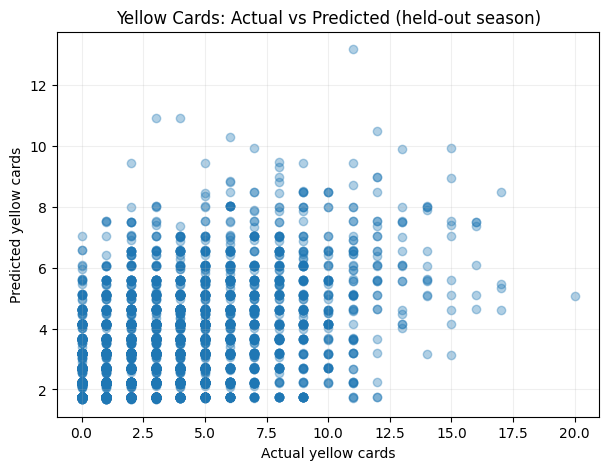

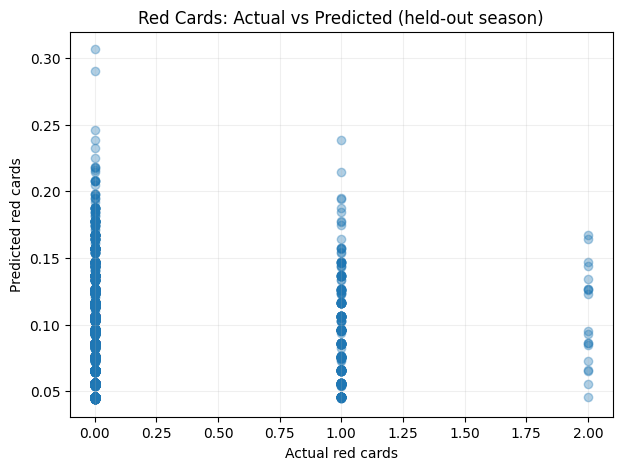

In [6]:
yellow_pred = yellow_models["Linear Regression"].predict(X_test)
red_pred = red_models["Linear Regression"].predict(X_test)

comparison = test_data[["season", "next_season", "player_id", "player_name"]].copy()
comparison["actual_yellow"] = test_data["next_yellow"].to_numpy()
comparison["predicted_yellow"] = yellow_pred
comparison["actual_red"] = test_data["next_red"].to_numpy()
comparison["predicted_red"] = red_pred

display(comparison.head(10).round(2))

plt.figure(figsize=(7, 5))
plt.scatter(test_data["next_yellow"], yellow_pred, alpha=0.35)
plt.xlabel("Actual yellow cards")
plt.ylabel("Predicted yellow cards")
plt.title("Yellow Cards: Actual vs Predicted (held-out season)")
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(test_data["next_red"], red_pred, alpha=0.35)
plt.xlabel("Actual red cards")
plt.ylabel("Predicted red cards")
plt.title("Red Cards: Actual vs Predicted (held-out season)")
plt.grid(alpha=0.2)
plt.show()

## 7. Fit final models for the player lookup demo

After the holdout evaluation, we refit the regression models on all available labeled examples with target seasons through 2019. The incomplete 2020 season is not used as a target. The prediction function uses the player's latest available source-season record no later than 2019.

**Limitation:** the data is historical and ends in February 2021. Predictions are estimates, not guarantees. Red-card counts are sparse, so check the zero-baseline results before claiming the red-card model is useful.

In [7]:
final_data = samples[samples["next_season"] <= 2019].copy()
X_final = final_data[features]

final_yellow_model = LinearRegression().fit(X_final, final_data["next_yellow"])
final_red_model = LinearRegression().fit(X_final, final_data["next_red"])

def predict_cards_for_player(player_name):
    if not isinstance(player_name, str) or not player_name.strip():
        return "Please enter a valid player name."

    matches = player_season[
        player_season["player_name"].str.contains(
            player_name.strip(), case=False, na=False, regex=False
        )
        & (player_season["season"] <= 2019)
    ].copy()

    if matches.empty:
        return f"No player matching '{player_name}' was found in the available seasons."

    # If the search returns several players, show options instead of silently choosing one.
    player_options = matches[["player_id", "player_name"]].drop_duplicates()
    if len(player_options) > 1:
        return (
            "More than one player matched. Please use a more specific name.\n"
            + player_options.head(10).to_string(index=False)
        )

    latest = matches.sort_values("season").iloc[[-1]]
    X_player = latest[features]

    pred_yellow = max(0, float(final_yellow_model.predict(X_player)[0]))
    pred_red = max(0, float(final_red_model.predict(X_player)[0]))

    source_season = int(latest["season"].iloc[0])
    return (
        f"Player: {latest['player_name'].iloc[0]}\n"
        f"Source season: {source_season}\n"
        f"Estimated yellow cards for the following season: {pred_yellow:.2f}\n"
        f"Estimated red cards for the following season: {pred_red:.2f}\n"
        "Note: these are model estimates, not guaranteed outcomes."
    )

PLAYER_NAME = "Lionel Messi"  # Change this to test another player
print(predict_cards_for_player(PLAYER_NAME))

Player: Lionel Messi
Source season: 2019
Estimated yellow cards for the following season: 5.06
Estimated red cards for the following season: 0.11
Note: these are model estimates, not guaranteed outcomes.


## 8. Project notes

- This notebook uses a time-based holdout, not a random split.
- Results should be reported exactly as printed by the notebook.
- Do not describe predictions as guaranteed or claim high accuracy without evidence.
- Add the dataset's original source and license to the README before publishing.